305
Mean: 1.2211812011169385, Median: 1.0085347144145065, IQR: 1.0107657153009078, Range: 15.641693502245605


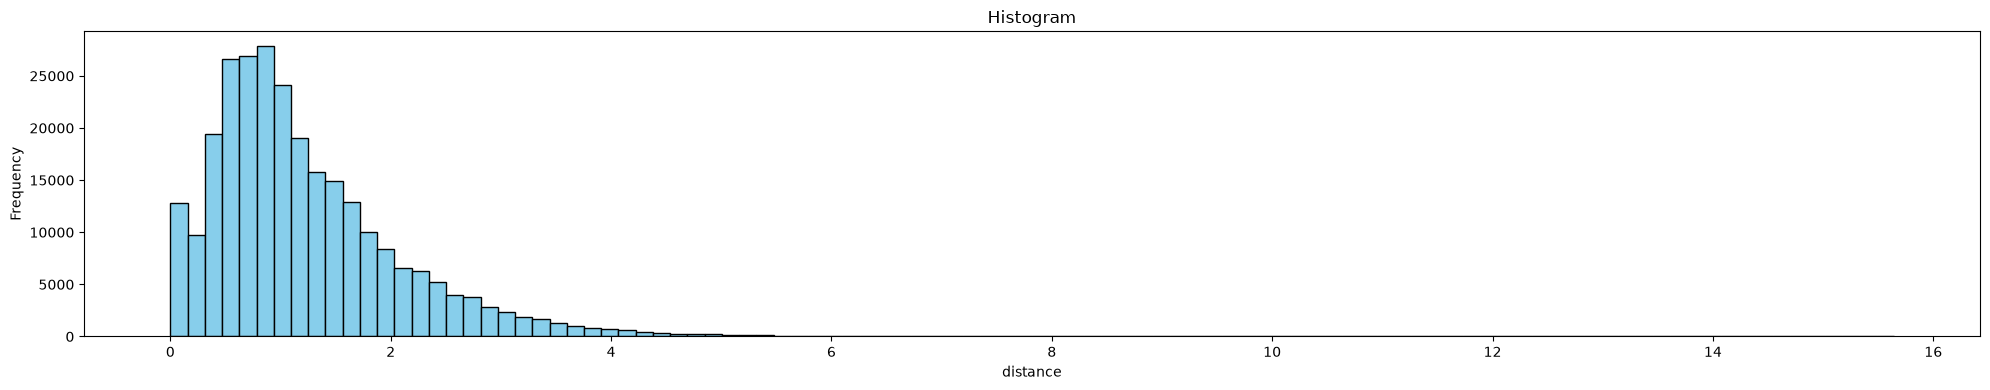

In [2]:
import numpy as np
import matplotlib.pyplot as mpl
import pandas as pd
from datetime import datetime
df = pd.read_csv("~/BlueBike_DS_Project/DATA/202304-bluebikes-tripdata.csv")
date_format = "%Y-%m-%d %H:%M:%S"
start_dt = datetime.strptime(df['started_at'][0].replace("  ", " "), date_format)
end_dt = datetime.strptime(df['ended_at'][0].replace("  ", " "), date_format)

seconds = int(((end_dt-start_dt)).total_seconds())

print(seconds)

np.mean(df['tripduration'])
def haversine_vectorized(lat1, lon1, lat2, lon2, unit="miles"):
    # Convert degrees to radians
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    # Haversine formula
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    c = 2 * np.arcsin(np.sqrt(a))

    # Earth radius
    radius = 3959 if unit == "miles" else 6371

    return c * radius


# Calculate instantly across all rows
distance = haversine_vectorized(
    df["start_lat"], df["start_lng"], df["end_lat"], df["end_lng"], unit="miles"
)

pd_mean = distance.mean()
pd_median = distance.median()
q1_pd = distance.quantile(0.25)
q3_pd = distance.quantile(0.75)
pd_iqr = q3_pd - q1_pd
pd_range = distance.max() - distance.min()

print(f"Mean: {pd_mean}, Median: {pd_median}, IQR: {pd_iqr}, Range: {pd_range}")

fig, ax = mpl.subplots(figsize=(20, 4))


ax.hist(distance, bins=100, color="skyblue", edgecolor="black")
ax.set_title("Histogram")
ax.set_xlabel("distance")
ax.set_ylabel("Frequency")

mpl.tight_layout()
mpl.show()
